## Support Vector Machine

Used SVM to build and train a model using human cell records, and classify cells to whether the samples are benign (mild state) or malignant (evil state).

SVM works by mapping data to a high-dimensional feature space so that data points can be categorized, even when the data are not otherwise linearly separable (This gets done by kernel function of SVM classifier). A separator between the categories is found, then the data is transformed in such a way that the separator could be drawn as a hyperplane.

### import libraries

In [2]:
# import libraries

# data manipulation
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# data preprocessing
from sklearn.model_selection import train_test_split

# classifier
from sklearn.svm import SVC

# evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# float display
pd.options.display.float_format = '{:0.2f}'.format

# system
import os

# ignore warnings
import warnings
warnings.filterwarnings('ignore')

from PIL import Image

dir_path = r"C:\Users\Admin\Desktop\CQF Course\Module 4\Python Labs\Support Vector Machine"


## Data collection

In [4]:
path = os.path.join(dir_path,'cell_samples.csv')
df = pd.read_csv(path, index_col=0) 

## EDA (Exploratory Data Analysis)

In [5]:
df.describe()

,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BlandChrom,NormNucl,Mit,Class
count,699.00,699.00,699.00,699.00,699.00,699.00,699.00,699.00,699.00
mean,4.42,3.13,3.21,2.81,3.22,3.44,2.87,1.59,2.69
std,2.82,3.05,2.97,2.86,2.21,2.44,3.05,1.72,0.95
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00
25%,2.00,1.00,1.00,1.00,2.00,2.00,1.00,1.00,2.00
50%,4.00,1.00,1.00,1.00,2.00,3.00,1.00,1.00,2.00
75%,6.00,5.00,5.00,4.00,4.00,5.00,4.00,1.00,4.00
max,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,4.00


## Cleaning DataSet

In [6]:
df.isnull().sum()

# one column has '?' values and dtype is 'string'
df.dtypes
mask_index = df.loc[df['BareNuc'] == '?',:].index
df.drop(index = mask_index, inplace = True)
df['BareNuc'] = df['BareNuc'].astype('int')   

## Distribution of Classes

In [7]:
# here class =2 is benign and class 4 is malignant

df['Class'].value_counts()

2    443
4    239
Name: Class, dtype: int64

## Feature Selection

In [8]:
X = df.drop(columns = 'Class')

## Label Definition

In [9]:
y = df['Class']

## Split Data

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.2, shuffle=False,random_state=0)

## Model

The SVM algorithm offers a range of kernel functions to perform its procesing. Basically, mapping data into a higher dimensional space is called kernelling.The mathematical function used for the transformation is called kernel function and can be of different typs:
- Linear
- Polynomial
- Radical Basis Function(RBF)
- Sigmoid

Each of these functions has its own pros/cons, characteristics and equations. As there is no easy way of knowing which function performs best with given dataset and hence, we use each of these to compare results

In [11]:
model = SVC(kernel = 'linear', C= 2, gamma = 'auto')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [12]:
y_pred

array([2, 2, 2, 2, 4, 2, 2, 4, 4, 4, 4, 2, 2, 4, 2, 2, 2, 2, 2, 2, 4, 4,
       2, 2, 2, 4, 2, 4, 2, 4, 4, 4, 2, 4, 2, 2, 2, 2, 2, 2, 2, 2, 4, 4,
       4, 2, 2, 4, 2, 4, 4, 4, 2, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 4, 2,
       2, 2, 2, 2, 2, 4, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 4, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 2, 2,
       2, 2, 4, 4, 4], dtype=int64)

## Prediction Quality

### Confusion Matrix

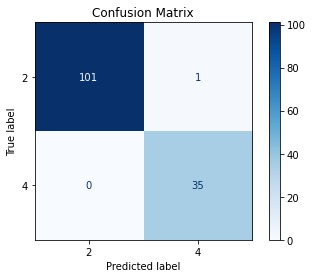

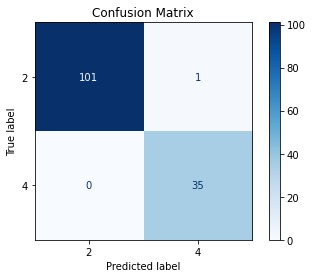

In [13]:
confusion_matrix(y_test, y_pred)           # confusion_matrix()

# ConfusionMatrixDisplay.from_estimator()
disp = ConfusionMatrixDisplay.from_estimator(estimator = model, X= X_test, y= y_test,labels =model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# ConfusionMatrixDisplay.from_predictor()
disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels =model.classes_ , cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

### Classification Report

In [14]:
# Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           2       1.00      0.99      1.00       102
           4       0.97      1.00      0.99        35

    accuracy                           0.99       137
   macro avg       0.99      1.00      0.99       137
weighted avg       0.99      0.99      0.99       137



### Receiver Operator Characterisitc Curve (ROC)

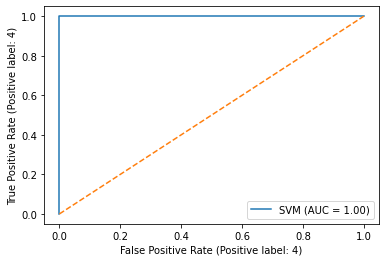

In [17]:
roc_curve(y_test, y_pred,pos_label=4)           # roc_curve()

RocCurveDisplay.from_estimator(model,X_test,y_test,pos_label = 4,name='SVM' )  # RocCurveDisplay.from_estimator()
plt.plot([0,1],[0,1], ls = '--')
plt.show()